# 1. Intorucdution to LangChain

## 1.1 what is LangGraph?
- LangGraph is a rramework from langhcain used to build stateful, multi-agent and graph-based applications.
- It allow us to define workflows as graph werhe each node perform a specific task and egges contrl the flow between nodes.
- LangGraph is useful for building complex applicatiions like agentic workflows, chatbots, RAG systems and multi-step automation.

## 1.2 why LangGraph?
- Traditional LLM applications are linear and stateless, which are limited for complex use cases.
- LangGraph provides state management, conditional routing, loops and human-in-the-loop support.
- It helps in creating more reliable, controllable and scalable LLM applications.

## 1.3 Key Features
- Graph-based workflow design
- State management across steps
- Conditional routing and branching
- Support for loops and iterative workflows
- Multi-agent systems
- Human-in-the-loop integration

## 1.4 Basic Architecture
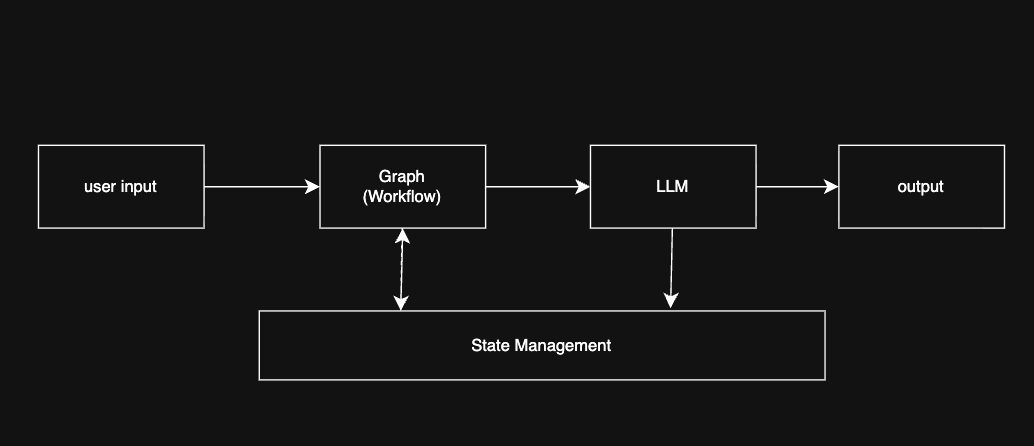

## 1.5 Core Components
- State : Shared data that flows between nodes.
- Node : A function or agent that performs a task.
- Edge : Defines the transition from one node to another.
- Graph : Collection of nodes and edges that define the workflow.
- Tool : External function or API used by nodes.
- LLM : Language model used for reasoning and generating responses.

## 1.6 Simple Example Workflow
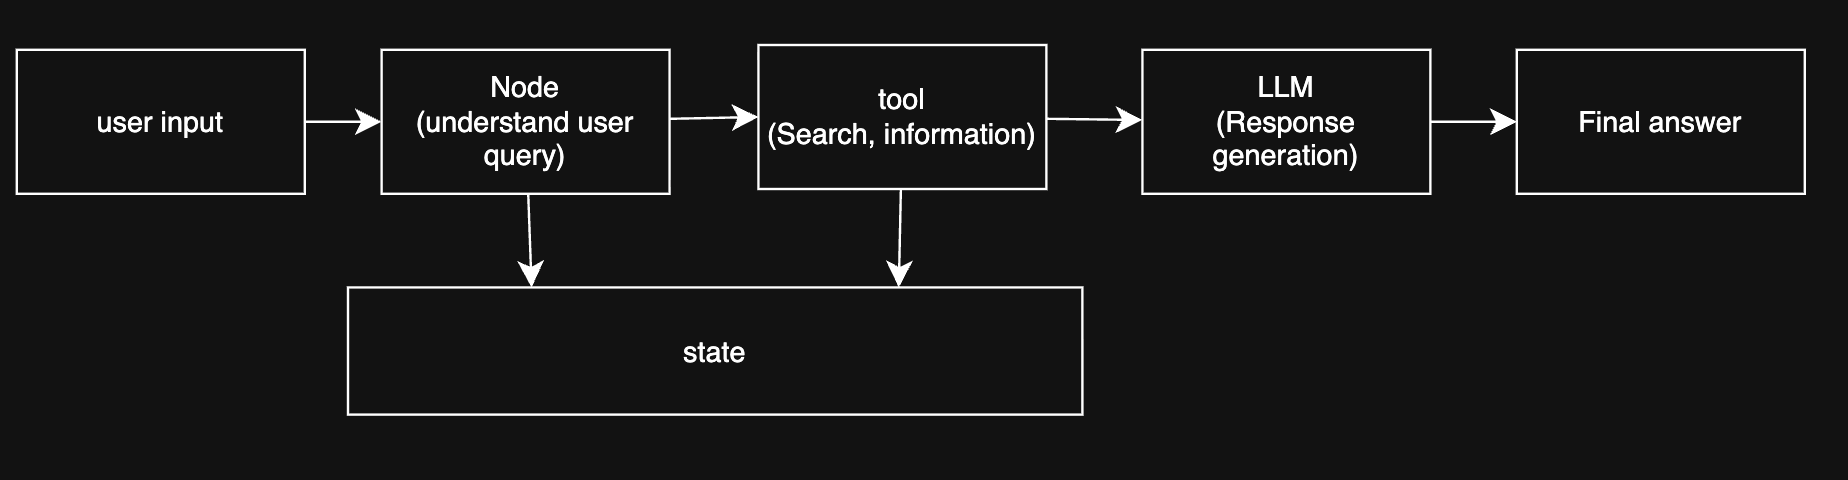

## 1.7 Use Cases
- RAG-based Q&A systems
- Multi-agent research and analysis
- Customer support automation
- Document processing workflows
- Data analysis and reporting
- Agentic AI applications
- Human-in-the-loop (approval, review, feedback)

## 1.8 LangGraph vs LangChain Chains
| Feature | LangChain Chains | LangGraph |
| :--- | :--- | :--- |
| **Workflow Type** | Linear | Graph-based |
| **State Management** | Limited | Built-in |
| **Conditional Routing** | Difficult | Easy |
| **Loops / Iterations** | Not supported | Supported |
| **Multi-Agent Support** | Limited | Native support |
| **Complex Workflows** | Hard to manage | Easier and scalable |

## 1.9 Advantages
* Better control over workflow execution.
* Supports complex, real-world use cases.
* Stateful and reliable applications.
* Easy integration with LangChain ecosystem.
* Flexible and extensible design.

## 1.10 Limitations
* Slightly steeper learning curve.
* More configuration compared to simple chains.
* Need to manage state and graph design carefully.
* Not always required for simple use cases.
* Performance depends on proper graph design.

## 1.11 Summary
* **LangGraph** helps us build stateful and graph-based LLM applications.
* It is more powerful than traditional chains.
* It is widely used for agentic systems, RAG and complex automation workflows.

# 2. StateGraph Fundamentals

## 2.1 What is State?

* State is the shared data that flows between nodes.
* Usually defined with `TypedDict` or `Pydantic`.
* Each node reads state and returns updates.

## 2.2 Example State Schema

```python
class ChatState(TypedDict):
    question: str
    answer: str
    steps: list[str]
```

## 2.3 Nodes
- A node is a Python function or callable.
- It performs one task.
- It returns partial state updates.

## 2.4 Edges
- Edges control transitions.
- Normal edges define order.
- Conditional edges choose branches.

## 2.5 START and END
- START is the entry point.
- END finishes execution.

## 2.6 Reducers
- Reducers merge concurrent updates.
- Useful for lists, messages, and aggregated outputs.
- `operator.add`

## Sample Flow
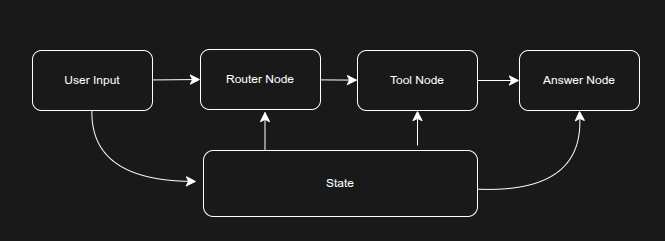

## 2.8 Best Practices
- Keep state minimal.
- Use clear field names.
- Validate outputs.
- Avoid storing unnecessary data.



# 3. Building Your First Graph

## 3.1 Goal
- Take user input.
- Process it in one node.
- Return a result.

## 3.2 Python Example
```python
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class MyState(TypedDict):
    user_input: str
    result: str

def process(state: MyState):
    return {"result": f"Echo: {state['user_input']}"}

builder = StateGraph(MyState)
builder.add_node("process", process)
builder.add_edge(START, "process")
builder.add_edge("process", END)

graph = builder.compile()
```

## 3.3 Invoke the Graph
- `output = graph.invoke({"user_input": "Hello"})`


## 3.4 Expected Result
- `{'user_input': 'Hello', 'result': 'Echo: Hello'}`


## 3.5 Workflow Diagram
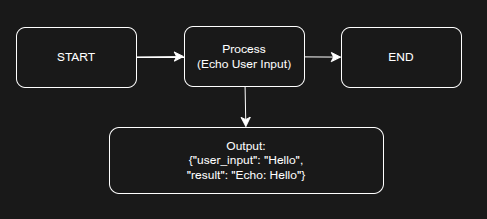

## 3.6 Key Takeaways
- Graphs are built first then compiled.
- Nodes return partial state.
- invoke() runs the workflow.

# 4. Conditional Routing & Branching

## 4.1 Why Routing?
* Different queries need different paths.
* Routing improves efficiency.
* Useful for tools, escalation, and fallbacks.

## 4.2 Router Node
* A router reads state and returns the next path label.

## 4.3 Routing Example

```python
def router(state):
    return "search" if state["need_search"] else "answer"

builder.add_conditional_edges(
    "decide",
    router,
    {"search": "tool", "answer": "respond"}
)
```

## 4.4 Common Routing Cases
* search vs direct answer
* human review vs auto-approve
* retry vs finish

## 4.5 Branching Diagram
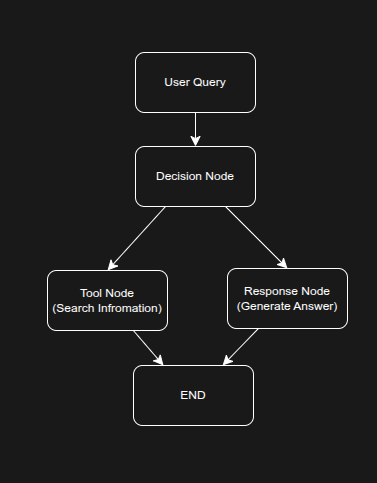

## 4.6 Design Tips
* Keep routing logic simple.
* Log branch decisions.
* Define safe defaults.

## 4.7 Summary
* Conditional edges make workflows dynamic and scalable.

# 5. Loops, Iteration & Retry

## 5.1 When do we use loops?
* Refine answers.
* Validate outputs.
* Retry failed tool calls.
* Continue until a condition is met.

## 5.2 Common Pattern
* `draft` -> `review` -> `revise`
* Loop until quality threshold is reached.

## 5.3 Retry Condition

```python
def should_retry(state):
    return "revise" if state["score"] < 8 else END
```

## 5.4 Iterative Workflow
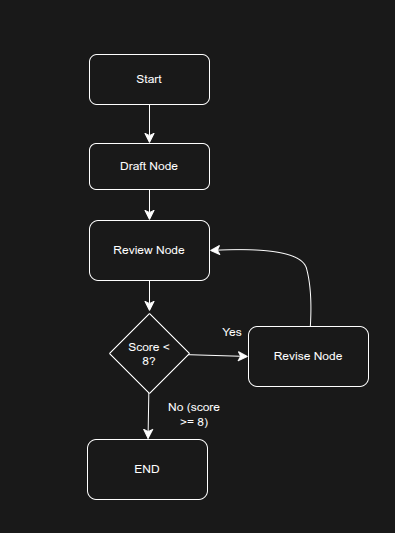

## 5.5 Benefits
* More reliable outputs.
* Better control.
* Supports self-correction.

## 5.6 Cautions
* Avoid infinite loops.
* Add max retries.
* Store review scores in state.

## 5.7 Summary
* Loops are one of LangGraph's strongest features for agentic systems.

# 6. Memory & Checkpointing

## 6.1 Why Memory Matters
* Chat apps need continuity.
* Workflows may pause and resume.
* State history helps debugging and auditing.

## 6.2 Checkpointer Concept
* A checkpointer saves state snapshots by thread.
* Each run can resume from prior progress.

## 6.3 Python Example

```python
from langgraph.checkpoint.memory import InMemorySaver

memory = InMemorySaver()
graph = builder.compile(
    checkpointer=memory
)
config = {"configurable": {
    "thread_id": "demo-1"
}}
```

## 6.4 Invoke with Memory

```python
graph.invoke({"messages": []}, config=config)
```

## 6.5 What Gets Saved?
* state values
* step history
* thread-specific progress

## 6.6 Memory Diagram
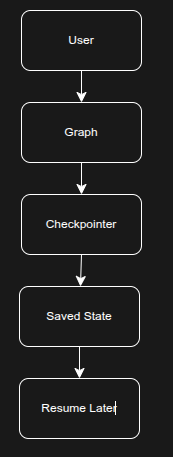

## 6.7 Best Practices
* Use unique thread IDs.
* Persist important conversations.
* Choose the right backend for production.

# 7. Human-in-the-Loop

## 7.1 Why Human Review?
* Reduce risk.
* Improve trust.
* Review sensitive or high-impact decisions.

## 7.2 Interrupt Pattern
* Pause the graph and ask for approval before continuing.

## 7.3 Python Example

```python
from langgraph.types import interrupt, Command

def approval_node(state):
    decision = interrupt({"draft": state["draft"]})
    return {"approved": decision}
```

## 7.4 Resume Example

```python
graph.invoke(input_state, config=config)
graph.invoke(Command(resume=True), config=config)
```

## 7.5 Approval Flow
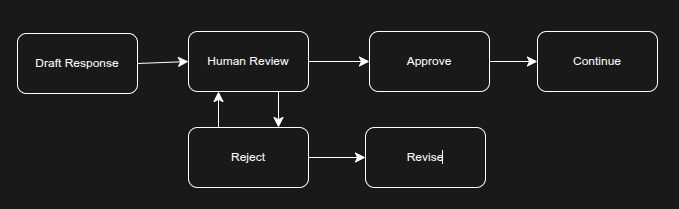

## 7.6 Real Use Cases
* Legal review
* Content moderation
* Customer support escalation
* Finance approvals

## 7.7 Best Practices
* Capture reviewer feedback.
* Log decisions.
* Design easy resume steps.

# 8. Tool Calling & Agents

## 8.1 What is Tool Calling?
* The model decides when to call external functions.
* Tools extend an agent beyond pure text generation.

## 8.2 Typical Agent Loop
1. Read message.
2. Decide tool.
3. Call tool.
4. Inspect result.
5. Answer user.

## 8.3 Simple Example

```python
from langgraph.prebuilt import create_react_agent

agent = create_react_agent(model, tools=[search_tool])

result = agent.invoke({
    "messages": [("user", "Find top AI trends")]
})
```

## 8.4 Agent Workflow Diagram
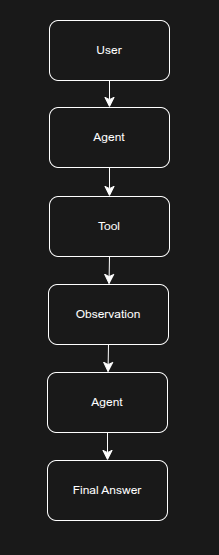

## 8.5 Best Practices
* Write clear tool descriptions.
* Validate tool arguments.
* Keep tool outputs structured.

## 8.6 Common Use Cases
* search
* database lookup
* calculator
* API orchestration
* RAG retrieval

## 8.7 Summary

* Tool use makes agents more capable and grounded.

# 9. Multi-Agent Systems

## 9.1 What is Multi-Agent System?
* Multiple specialized agents collaborate.
* Each agent has a focused role.
* This improves modularity.

## 9.2 Common Roles
* planner
* researcher
* writer
* reviewer

## 9.3 Coordination Styles
* supervisor pattern
* handoff pattern
* pipeline pattern

## 9.4 Benefits
* better specialization
* easier scaling
* clearer separation of concerns

## 9.5 Architecture Diagram
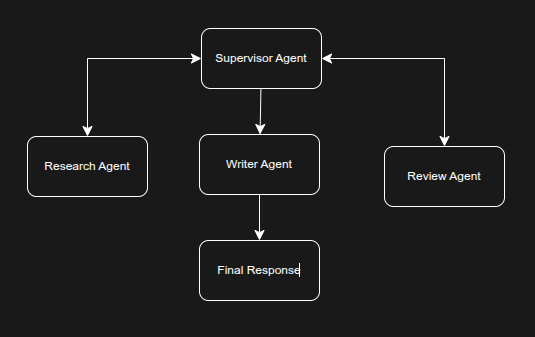

## 9.6 Challenges
* extra cost and latency
* coordination complexity
* shared-state design

## 9.7 When to Use It
* research assistants
* enterprise workflows
* long tasks with multiple skills

## 9.8 Summary
* Use multi-agent design when one agent becomes too overloaded.